# Olist — Modelo de risco de atraso na entrega
**Notebook 02** | Complementa a EDA (`01_eda_olist.ipynb`), onde vimos que o atraso é o principal fator de nota baixa.

## Problema de negócio
No momento em que um pedido é feito, dá para estimar **qual a chance de ele chegar atrasado**? Se der, a empresa pode agir *antes* do problema: avisar o cliente, priorizar o envio ou ajustar o prazo prometido.

## Desenho (decisões que evitam resultados inflados)
| Decisão | Por quê |
|---|---|
| **Alvo = entregue depois da data prometida** | É o mesmo conceito de atraso da EDA |
| **Só atributos conhecidos na hora da compra** | Datas de entrega, status e nota só existem depois: usá-los seria vazamento de informação |
| **Validação temporal em janelas móveis** | Treina com o passado e testa no mês seguinte (12 testes: set/2017 a ago/2018). Sorteio aleatório misturaria futuro e passado |
| **Treino só com desfechos já conhecidos no corte** | Em produção, um pedido ainda em trânsito não tem rótulo |
| **Métricas para classes desbalanceadas** | Só ~8% dos pedidos atrasam; acurácia seria inútil. Uso AUC, captura nos X% de maior risco e *lift* |

**Por que não prever a nota?** Porque a nota depende da entrega, que ainda não aconteceu na hora da compra. Prever nota exigiria dados do futuro.

O código de atributos e avaliação está em `src/atraso.py`.

In [1]:
import sys, sqlite3
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import atraso as A

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
AZUL, LARANJA, CINZA, VERMELHO = "#2563eb", "#f59e0b", "#94a3b8", "#dc2626"
pd.options.display.float_format = "{:,.3f}".format

con = sqlite3.connect("../olist.db")
d = A.montar_dataset(con)
print(f"Pedidos entregues (jan/2017–ago/2018): {len(d):,}  |  taxa de atraso: {d.y.mean():.1%}")
print(f"Atributos disponíveis: {len(A.PEDIDO)} do pedido + 2 de contexto operacional (congestionamento)")

Pedidos entregues (jan/2017–ago/2018): 96,203  |  taxa de atraso: 8.1%
Atributos disponíveis: 13 do pedido + 2 de contexto operacional (congestionamento)


## 1. Por que este problema é difícil: o atraso não é estável no tempo

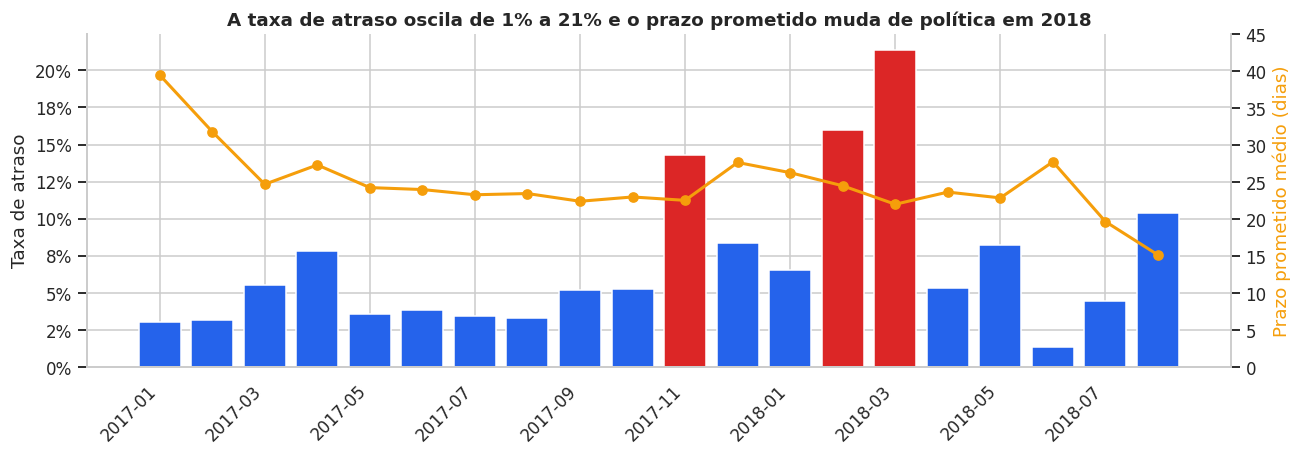

Taxa de atraso mensal: mínimo 1.4% (2018-06), máximo 21.4% (2018-03)
Prazo prometido médio: 24.1 dias (mai/17–jun/18)  →  19.7 (jul/18)  →  15.2 (ago/18)


In [2]:
mes = d.groupby("ym").agg(atraso=("y", "mean"), prazo=("prazo_prometido", "mean"), n=("y", "size"))

fig, ax = plt.subplots(figsize=(12, 4.3))
ax.bar(mes.index, mes.atraso, color=[VERMELHO if v > 0.12 else AZUL for v in mes.atraso])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_ylabel("Taxa de atraso")
ax.set_xticks(range(0, len(mes), 2)); ax.set_xticklabels(mes.index[::2], rotation=45, ha="right")
ax2 = ax.twinx(); ax2.plot(mes.index, mes.prazo, color=LARANJA, marker="o", lw=2)
ax2.set_ylabel("Prazo prometido médio (dias)", color=LARANJA); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax2.set_ylim(0, 45)
ax.set_title("A taxa de atraso oscila de 1% a 21% e o prazo prometido muda de política em 2018")
plt.tight_layout(); plt.savefig("../reports/figures/07_atraso_no_tempo.png", bbox_inches="tight"); plt.show()

print(f"Taxa de atraso mensal: mínimo {mes.atraso.min():.1%} ({mes.atraso.idxmin()}), máximo {mes.atraso.max():.1%} ({mes.atraso.idxmax()})")
print(f"Prazo prometido médio: {mes.prazo.loc['2017-05':'2018-06'].mean():.1f} dias (mai/17–jun/18)  →  {mes.prazo['2018-07']:.1f} (jul/18)  →  {mes.prazo['2018-08']:.1f} (ago/18)")

Dois fatos moldam todo o projeto:
1. **Surtos episódicos** (Black Friday em nov/2017, fev–mar/2018) elevam o atraso para 14–21%, e depois ele volta ao normal.
2. **Em jul–ago/2018 a plataforma encurtou os prazos prometidos** (de ~24 para ~15 dias). Uma relação aprendida no passado (por exemplo, "prazo curto não importa") deixa de valer. Isso é *concept drift*.

Um modelo que memoriza o passado vai falhar justamente quando a operação mudar. Por isso o desenho prioriza **estabilidade ao longo do tempo**, não só desempenho num único período.

## 2. Atributos e modelos candidatos

**Atributo-chave: a "folga" do prazo.** O prazo prometido sozinho diz pouco (um prazo de 20 dias é folgado para São Paulo→São Paulo e apertado para Sul→Nordeste). O que importa é o **quanto o prazo prometido excede o tempo típico de entrega daquela rota** (estado do vendedor → estado do cliente):

- `tipico` = mediana de dias de entrega da rota, calculada **só com entregas já concluídas antes da data de corte**;
- `folga` = prazo prometido − tempo típico (em dias) e `folga_pct` = prazo ÷ tempo típico.

Comparo seis candidatos, do mais simples ao mais complexo:

In [3]:
print(pd.DataFrame({
    "modelo": list(A.catalogo_modelos().keys()),
    "atributos": [len(c) for c, _, _ in A.catalogo_modelos().values()],
}).to_string(index=False))

                                    modelo  atributos
           Baseline: taxa histórica por UF          1
             Logística: só prazo prometido          1
      Logística: folga da rota (histórico)          4
Logística: folga da rota (últimos 90 dias)          4
    Gradient boosting: atributos do pedido         13
                   Gradient boosting: tudo         19


## 3. Avaliação em janelas móveis (12 testes fora do tempo)
Para cada mês de teste (set/2017 → ago/2018), o modelo é treinado só com o que se sabia até o início daquele mês.

In [4]:
meses = sorted(d.ym.unique())[8:]          # meses de teste: 2017-09 a 2018-08
resultados, prev = A.avaliar_janelas(d, meses)

resumo = (resultados.groupby("modelo")
          .agg(auc_medio=("auc", "mean"), auc_dp=("auc", "std"), auc_pior_mes=("auc", "min"),
               captura_top10=("cap10", "mean"), precisao_top10=("prec10", "mean"), lift_top10=("lift10", "mean"))
          .sort_values("auc_medio", ascending=False))
for c in ["captura_top10", "precisao_top10"]:
    resumo[c] = resumo[c] * 100
resumo = resumo.rename(columns={"captura_top10": "captura_top10_%", "precisao_top10": "precisao_top10_%"})
print("Médias dos 12 meses de teste. AUC 0,5 = acaso. 'captura_top10' = % dos atrasos reais entre os 10% de maior risco.")
resumo

Médias dos 12 meses de teste. AUC 0,5 = acaso. 'captura_top10' = % dos atrasos reais entre os 10% de maior risco.


,auc_medio,auc_dp,auc_pior_mes,captura_top10_%,precisao_top10_%,lift_top10
modelo,,,,,,
Logística: folga da rota (últimos 90 dias),0.694,0.049,0.617,26.842,22.205,2.687
Logística: folga da rota (histórico),0.675,0.061,0.590,24.491,19.136,2.451
Gradient boosting: atributos do pedido,0.650,0.087,0.444,23.308,19.069,2.333
Baseline: taxa histórica por UF,0.602,0.090,0.369,14.944,13.042,1.496
Gradient boosting: tudo,0.588,0.066,0.497,13.607,10.609,1.362
Logística: só prazo prometido,0.548,0.103,0.443,11.637,8.576,1.165


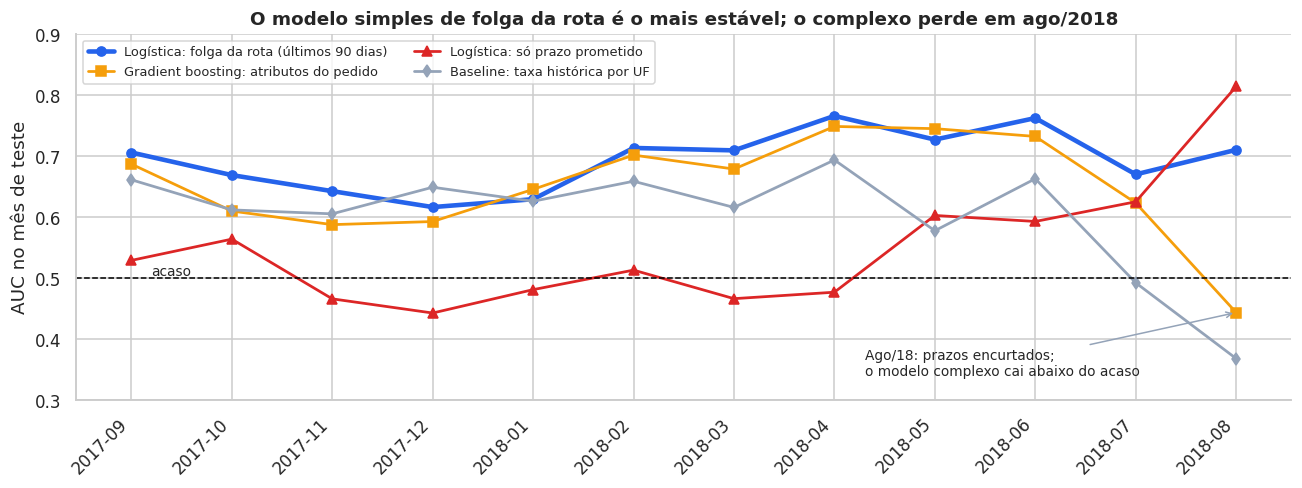

In [5]:
pv = resultados.pivot(index="mes", columns="modelo", values="auc")
fig, ax = plt.subplots(figsize=(12, 4.6))
estilo = {A.FINAL: (AZUL, 3, "o"), "Gradient boosting: atributos do pedido": (LARANJA, 1.8, "s"),
          "Logística: só prazo prometido": (VERMELHO, 1.8, "^"), "Baseline: taxa histórica por UF": (CINZA, 1.8, "d")}
for nome, (cor, lw, mk) in estilo.items():
    ax.plot(pv.index, pv[nome], color=cor, lw=lw, marker=mk, label=nome)
ax.axhline(0.5, color="black", ls="--", lw=1); ax.text(0.2, 0.505, "acaso", fontsize=9)
ax.set_ylim(0.3, 0.9); ax.set_ylabel("AUC no mês de teste")
ax.set_xticks(range(len(pv.index))); ax.set_xticklabels(pv.index, rotation=45, ha="right")
ax.annotate("Ago/18: prazos encurtados;\no modelo complexo cai abaixo do acaso", xy=(11, pv.loc["2018-08", "Gradient boosting: atributos do pedido"]),
            xytext=(7.3, 0.34), arrowprops=dict(arrowstyle="->", color=CINZA), fontsize=9)
ax.set_title("O modelo simples de folga da rota é o mais estável; o complexo perde em ago/2018")
ax.legend(loc="upper left", fontsize=8.5, ncol=2)
plt.tight_layout(); plt.savefig("../reports/figures/08_auc_por_mes.png", bbox_inches="tight"); plt.show()

### O que a comparação ensina
- **Simplicidade venceu.** A regressão logística com 4 atributos de prazo/rota supera o gradient boosting com mais atributos, tanto na média quanto na estabilidade (menor desvio-padrão e nenhum mês perto do acaso).
- **O prazo prometido sozinho é enganoso:** ele fica perto do acaso na maior parte dos meses e só "acerta" em ago/2018, quando a política mudou.
- **Mais atributos não ajudaram:** o gradient boosting "tudo" (pedido + rota + congestionamento) ficou ainda pior (AUC 0,59) que a versão só com atributos do pedido (0,65). Não isolei a causa; as hipóteses são que o congestionamento reflete surtos que não se repetem e que o modelo flexível se ajusta demais aos atributos de rota calculados dentro da própria amostra de treino.
- Os resultados absolutos são **moderados** (AUC ~0,69): o atraso depende de eventos que o dado de compra não captura (greves, clima, falhas do transportador). O valor está em *ordenar risco*, não em adivinhar cada atraso.

> **Nota de transparência.** Testei duas versões do tempo típico da rota (histórico completo e últimos 90 dias) e adotei a segunda depois de ver que ela vencia em 9 de 12 meses. Como a escolha usou os mesmos meses de teste, o resultado final tem um leve otimismo; por isso mostro as duas versões na tabela. A versão de 90 dias também é justificável a priori: ela se adapta quando a operação muda.

## 4. O modelo escolhido na prática (previsões 100% fora do tempo)
Uso as previsões do modelo final em todos os meses de teste (**74.206 pedidos, set/2017 a ago/2018**).

### 4.1 A folga do prazo ordena o risco de forma nítida

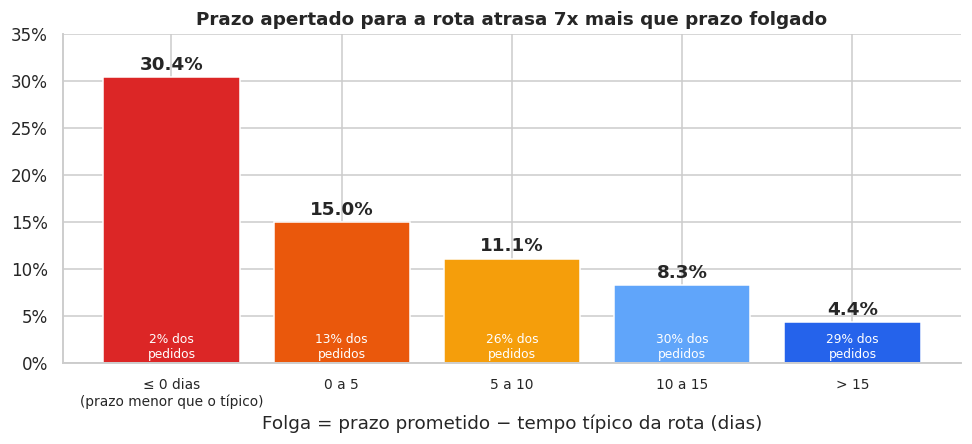

,pedidos,taxa_de_atraso,pct_dos_pedidos
faixa,,,
≤ 0 dias\n(prazo menor que o típico),1685,0.304,0.023
0 a 5,9650,0.150,0.130
5 a 10,19620,0.111,0.264
10 a 15,21981,0.083,0.296
> 15,21270,0.044,0.287


In [6]:
bins = [-np.inf, 0, 5, 10, 15, np.inf]
rotulos = ["≤ 0 dias\n(prazo menor que o típico)", "0 a 5", "5 a 10", "10 a 15", "> 15"]
prev["faixa"] = pd.cut(prev.folga_r, bins, labels=rotulos)
tab = prev.groupby("faixa", observed=True).agg(pedidos=("y", "size"), taxa_atraso=("y", "mean"))
tab["pct_dos_pedidos"] = tab.pedidos / len(prev)

fig, ax = plt.subplots(figsize=(9, 4.2))
barras = ax.bar(range(len(tab)), tab.taxa_atraso, color=[VERMELHO, "#ea580c", LARANJA, "#60a5fa", AZUL])
for i, (t, p) in enumerate(zip(tab.taxa_atraso, tab.pct_dos_pedidos)):
    ax.text(i, t + .008, f"{t:.1%}", ha="center", fontweight="bold"); ax.text(i, .006, f"{p:.0%} dos\npedidos", ha="center", fontsize=8, color="white")
ax.set_xticks(range(len(tab))); ax.set_xticklabels(tab.index, fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_xlabel("Folga = prazo prometido − tempo típico da rota (dias)")
ax.set_ylim(0, 0.35); ax.set_title("Prazo apertado para a rota atrasa 7x mais que prazo folgado")
plt.tight_layout(); plt.savefig("../reports/figures/09_atraso_por_folga.png", bbox_inches="tight"); plt.show()
tab.rename(columns={"taxa_atraso": "taxa_de_atraso"})

### 4.2 Quanto dos atrasos conseguimos antecipar? (curva de ganhos)
Se a empresa sinalizar os X% de pedidos com maior risco, que fração dos atrasos reais ela captura?

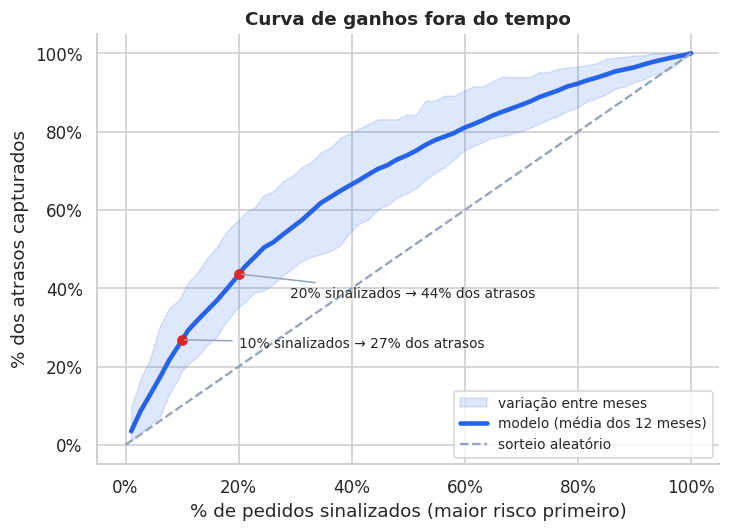

,captura dos atrasos,"precisão (dos sinalizados, % atrasam)",lift vs. taxa-base
% sinalizado,,,
5%,14.4%,23.0%,2.9x
10%,26.8%,22.2%,2.7x
20%,43.6%,18.6%,2.2x
30%,56.0%,16.3%,1.9x


In [7]:
ks = np.unique(np.round(np.r_[np.linspace(0.01, 1, 60), 0.10, 0.20], 4))
ganho = pd.DataFrame({k: prev.groupby("ym").apply(lambda x: A.captura_topk(x.y, x.p, k)) for k in ks})
fig, ax = plt.subplots(figsize=(6.8, 5))
ax.fill_between(ks, ganho.min(), ganho.max(), color=AZUL, alpha=.15, label="variação entre meses")
ax.plot(ks, ganho.mean(), color=AZUL, lw=3, label="modelo (média dos 12 meses)")
ax.plot([0, 1], [0, 1], color=CINZA, ls="--", label="sorteio aleatório")
for k, dx, dy in ((0.10, .10, -.02), (0.20, .09, -.06)):
    v = ganho.mean()[k]
    ax.scatter(k, v, color=VERMELHO, zorder=3)
    ax.annotate(f"{k:.0%} sinalizados → {v:.0%} dos atrasos", (k, v), xytext=(k + dx, v + dy), fontsize=9,
                arrowprops=dict(arrowstyle="-", color=CINZA))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("% de pedidos sinalizados (maior risco primeiro)"); ax.set_ylabel("% dos atrasos capturados")
ax.set_title("Curva de ganhos fora do tempo"); ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.savefig("../reports/figures/10_curva_de_ganhos.png", bbox_inches="tight"); plt.show()

linhas = []
for k in (0.05, 0.10, 0.20, 0.30):
    por_mes = prev.groupby("ym").apply(lambda x: pd.Series({
        "captura": A.captura_topk(x.y, x.p, k),
        "precisao": x.y.values[np.argsort(-x.p.values)[:int(len(x) * k)]].mean(),
        "prevalencia": x.y.mean()}))
    linhas.append({"% sinalizado": f"{k:.0%}", "captura dos atrasos": por_mes.captura.mean(),
                   "precisão (dos sinalizados, % atrasam)": por_mes.precisao.mean(),
                   "lift vs. taxa-base": (por_mes.precisao / por_mes.prevalencia).mean()})
pd.DataFrame(linhas).set_index("% sinalizado").style.format({"captura dos atrasos": "{:.1%}", "precisão (dos sinalizados, % atrasam)": "{:.1%}", "lift vs. taxa-base": "{:.1f}x"})

## 5. Cuidado com as probabilidades: use o modelo para *ordenar*, não como valor absoluto

In [8]:
f = resultados[resultados.modelo == A.FINAL][["mes", "prevalencia", "pred_medio", "auc"]].copy()
f["erro_de_calibracao"] = f.pred_medio - f.prevalencia
f = f.set_index("mes")
print("Taxa real de atraso x probabilidade média prevista pelo modelo, por mês:")
f.rename(columns={"prevalencia": "taxa_real", "pred_medio": "previsto_medio", "erro_de_calibracao": "previsto − real"})

Taxa real de atraso x probabilidade média prevista pelo modelo, por mês:


,taxa_real,previsto_medio,auc,previsto − real
mes,,,,
2017-09,0.052,0.046,0.706,-0.006
2017-10,0.053,0.042,0.669,-0.011
2017-11,0.143,0.044,0.643,-0.099
2017-12,0.084,0.030,0.617,-0.054
2018-01,0.066,0.043,0.630,-0.023
2018-02,0.160,0.059,0.714,-0.101
2018-03,0.214,0.069,0.710,-0.145
2018-04,0.053,0.069,0.766,0.016
2018-05,0.082,0.089,0.727,0.007


A probabilidade prevista **não é calibrada**: em surtos (nov/2017, fev–mar/2018) o modelo subestima o atraso e em períodos calmos (jun–jul/2018) superestima. Isso é esperado, pois o nível geral de atraso depende de eventos externos. Por isso, a recomendação é usar o escore para **ranquear e sinalizar o top X%** (a capacidade de ordenação se manteve em todos os meses: AUC entre 0,62 e 0,77), e **recalibrar mensalmente** se a probabilidade absoluta importar.

## 6. Conclusões

### Resultados
1. **É possível antecipar parte dos atrasos na hora da compra.** Sinalizando os 10% de pedidos de maior risco, o modelo captura em média **27% dos atrasos**, e dos pedidos sinalizados cerca de **22% realmente atrasam**, contra uma taxa-base de ~9% (lift de ~2,7x). Sinalizando 30%, capta 56% dos atrasos.
2. **O motivo é a folga do prazo, não o prazo bruto.** Pedidos cujo prazo prometido é menor ou igual ao tempo típico da rota atrasam **30%** das vezes; com folga acima de 15 dias, **4%**. Esse achado vale com ou sem modelo.
3. **Simplicidade venceu.** Quatro atributos em regressão logística (AUC médio 0,69; pior mês 0,62) superaram o gradient boosting com mais atributos (0,65), que ficou abaixo do acaso quando a política de prazo mudou em ago/2018.
4. **O desempenho é moderado.** Atrasos dependem de eventos que o pedido não revela (greves, clima, falhas de transportadora). O modelo serve para **triagem de risco**, não para garantias.

### Recomendações
| Prioridade | Ação | Base |
|---|---|---|
| 1 | **Calibrar o prazo prometido pela rota**: onde o prazo é menor que o tempo típico, estender a promessa ou reforçar a operação. Testar em A/B o efeito na conversão. | 2,3% dos pedidos têm prazo ≤ típico e atrasam 30% |
| 2 | **Triagem proativa**: sinalizar o top 10% de risco para aviso ao cliente, priorização no despacho e acompanhamento. | 27% dos atrasos concentrados em 10% dos pedidos |
| 3 | **Retreinar todo mês e monitorar o AUC**; investigar se ficar abaixo de ~0,6. | Concept drift documentado (política de prazo e surtos) |
| 4 | **Próximo passo de modelagem**: histórico de desempenho do vendedor e da transportadora calculado de forma rolante, e um modelo para *quantos dias* de atraso. | Atributos de vendedor não foram usados |

### Limitações
- **Poucos dados e curto período** (20 meses): 12 janelas de teste dão uma ideia da estabilidade, mas não garantem o futuro.
- **Leve otimismo na escolha da versão final** (descrito na seção 3).
- **No treino, o tempo típico da rota usa os mesmos pedidos** (e uma janela fixa), o que pode enfraquecer o aprendizado; **no teste ele é calculado apenas com o passado**, então as métricas reportadas não são infladas por isso.
- **Não há modelo de custo**: o benefício financeiro da ação preventiva não foi estimado, pois a base não traz custos de operação nem de compensação.
- **Associação, não causalidade:** prazo apertado está ligado a mais atraso, mas a plataforma pode apertar prazos justamente onde espera operação mais rápida.
- **Prazo prometido é decisão da plataforma:** o modelo aprende também a regra de estimativa dela, que mudou em 2018.